# Predict with all EpiHydra clocks at once

Builds one `MultiClockPredictor`: the frozen, LoRA-merged backbone from `best_model.pt` with one head per clock.

- `"age"` (always included) uses the head stored in `best_model.pt`.
- Every other clock uses `best_head_<clock>.pt` from `HEAD_PATH`.

Each batch goes through the backbone **once** and the hidden states fan out to every head. The output is a table of predictions (plus true labels where available) with one row per sample. Metrics come later.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [33]:
from pathlib import Path

# ── Which clocks to predict ──────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH.
# Or give a list, e.g. ["age", "horvath_age", "phenoage_age"]; "age" is always added first.
CLOCKS     = None

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/GSE41037/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks4_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261105_072540"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"           # LoRA backbone + the "age" head

# ── Model settings (must match training) ─────────────────────────
NUM_HEADS  = 4 # N clocks exlcuding "age" (chron age)
LORA_R     = 16
LORA_ALPHA = 8

SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 8
RANDOM_STATE = 42

# Where to save the prediction table (None = don't save)
OUT_CSV = None

## Imports

In [34]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_multiclock_dataloaders, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device: {device}")
print(f"Evaluating clocks: '{clock_names}'")

Using device: cuda
Evaluating clocks: '['age', 'grimageadapter_age', 'hannum_age', 'horvath_age', 'phenoage_age']'


## Load data, config and vocab

In [35]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

# MethylGPT pre-training config (layer sizes, number of CpGs, ...)
with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

# CpG vocabulary used for tokenisation
vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
One dataset carries every clock's label. Samples are kept if they have a label for at least one clock, so missing labels show up as NaN in the `_true` columns.

The saved training scalers from `HEAD_PATH/scalers.pkl` are passed in and reused. Any clock without a saved scaler (i.e. `"age"`) gets one fitted on this training split.

In [36]:
scalers = eu.load_scalers(HEAD_PATH)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = scalers,   # reused where available, fitted otherwise
    **SPLIT_RATIOS,
)
scalers = dataloader["scalers"]         # the scalers actually used, one per clock

Samples in meta : 720
Samples in CpG  : 720
Common samples  : 720
Samples after drop : 720
  age                 : 720 labeled
  grimageadapter_age  : 720 labeled
  hannum_age          : 720 labeled
  horvath_age         : 720 labeled
  phenoage_age        : 720 labeled

Vocab CpGs : 49,159 | Present : 22,287 (45.3%) | Missing : 26,872
ℹ  age                 : scaler fitted on all values (no-split mode).
ℹ  grimageadapter_age  : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Single multi-clock loader built (720 samples, no masking).



## Build the multi-clock model
Rebuilds the backbone the heads were trained on (LoRA adapters loaded from `best_model.pt`, merged and frozen), then loads one head per clock.

In [37]:
model = eu.build_multiclock_model(
    MODEL_PATH, vocab, pretrain_config,
    lora_ckpt   = LORA_CKPT,
    head_path   = HEAD_PATH,
    clock_names = clock_names,
    device      = device,
    num_heads   = NUM_HEADS,
    lora_r      = LORA_R,
    lora_alpha  = LORA_ALPHA,
)

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750/best_model.pt
  source run   : nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750
  source epoch : 85  (valid MAE 4.864)
  lora_r=16 lora_alpha=8 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head grimageadapter_age   <- best_head_grimageadapter_age.pt (epoch 46)
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 47)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 31)
  loaded head phenoage_age         <- best_head_phenoage_age.p

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


## Predict
One forward pass through the backbone per batch, shared across all heads. Loaders are rebuilt unshuffled so each row lines up with its sample ID.

In [38]:
loader = eu.ordered_loader(dataloader['loader'])
ids    = dataloader[f"df"].index
predictions  = eu.predict_multiclock(model, loader, scalers, device, clock_names, ids)

print(f"{len(predictions)} samples x {len(clock_names)} clocks")

720 samples x 5 clocks


## Prediction table

In [39]:
pred_cols = [f"{c}_pred" for c in clock_names]

# Predictions only (one column per clock)
display(predictions[pred_cols].astype(float).round(2))

,age_pred,grimageadapter_age_pred,hannum_age_pred,horvath_age_pred,phenoage_age_pred
ID,,,,,
GSM1007129,31.04,97.93,62.85,29.93,20.24
GSM1007130,33.68,92.55,59.37,30.68,17.02
GSM1007131,21.86,103.49,68.23,14.85,-3.86
GSM1007132,29.73,101.73,66.23,25.98,7.13
GSM1007133,21.49,103.23,68.19,13.99,-6.43
...,...,...,...,...,...
GSM1007844,53.79,65.16,59.85,54.97,48.89
GSM1007845,56.43,79.13,68.84,55.94,48.68
GSM1007846,55.27,74.08,66.96,56.25,52.59


In [40]:
# Full table: predicted and true values side by side, per clock
display(predictions)

if OUT_CSV is not None:
    predictions.to_csv(OUT_CSV)
    print(f"Saved to {OUT_CSV}")

,age_pred,age_true,grimageadapter_age_pred,grimageadapter_age_true,hannum_age_pred,hannum_age_true,horvath_age_pred,horvath_age_true,phenoage_age_pred,phenoage_age_true
ID,,,,,,,,,,
GSM1007129,31.038084,34.0,97.929871,119.167564,62.848022,68.469971,29.930412,32.351063,20.237883,32.180855
GSM1007130,33.683594,31.0,92.553200,112.687599,59.371407,69.254761,30.679905,31.564583,17.020103,22.814148
GSM1007131,21.857908,23.0,103.489418,108.186356,68.226212,67.907562,14.852365,20.298512,-3.861230,18.999407
GSM1007132,29.728514,31.0,101.733772,114.203201,66.228600,67.454964,25.984549,30.948977,7.127143,24.661562
GSM1007133,21.493162,23.0,103.233383,109.764069,68.187798,68.671944,13.992652,25.364004,-6.428607,8.292242
...,...,...,...,...,...,...,...,...,...,...
GSM1007844,53.792969,60.0,65.157776,131.083450,59.851601,70.966805,54.972317,62.588951,48.889809,51.043171
GSM1007845,56.429688,68.0,79.129807,137.426483,68.840866,72.196114,55.942253,67.149887,48.684418,58.111397
GSM1007846,55.269531,73.0,74.082321,139.377243,66.958496,72.783859,56.250866,75.051994,52.586830,60.201786


In [41]:
cross = eu.pairwise_metrics(predictions, clock_names)

for metric in eu.METRICS:
    display(eu.style_metric_table(cross[metric], metric))

True clock,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,,
age,7.811,82.729,33.622,7.408,10.085
grimageadapter_age,42.931,38.535,21.252,42.449,50.467
hannum_age,22.748,59.513,10.471,21.928,29.544
horvath_age,9.100,85.873,36.767,8.741,9.313
phenoage_age,17.483,96.100,46.994,17.123,13.693


True clock,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,,
age,0.774,0.727,0.648,0.781,0.703
grimageadapter_age,-0.161,-0.096,-0.049,-0.143,-0.133
hannum_age,0.231,0.281,0.301,0.251,0.215
horvath_age,0.773,0.722,0.645,0.782,0.699
phenoage_age,0.691,0.651,0.569,0.706,0.663


True clock,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
Pred clock,,,,,
age,0.590,-72.389,-684.044,0.593,0.306
grimageadapter_age,-9.797,-21.395,-329.078,-11.020,-13.976
hannum_age,-2.040,-38.170,-115.333,-2.280,-4.087
horvath_age,0.484,-78.361,-838.179,0.453,0.368
phenoage_age,-0.806,-99.747,-1414.962,-1.046,-0.292


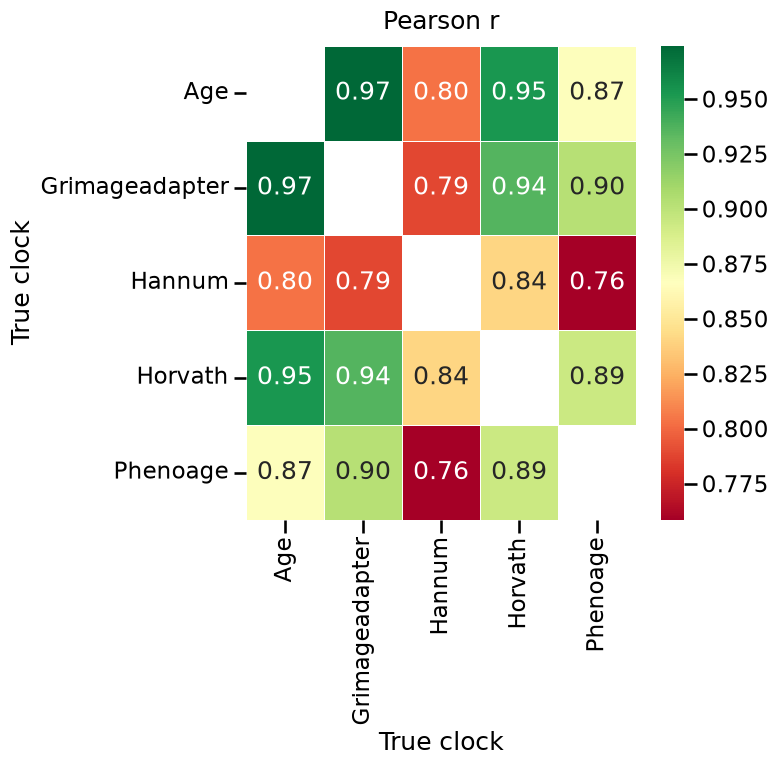

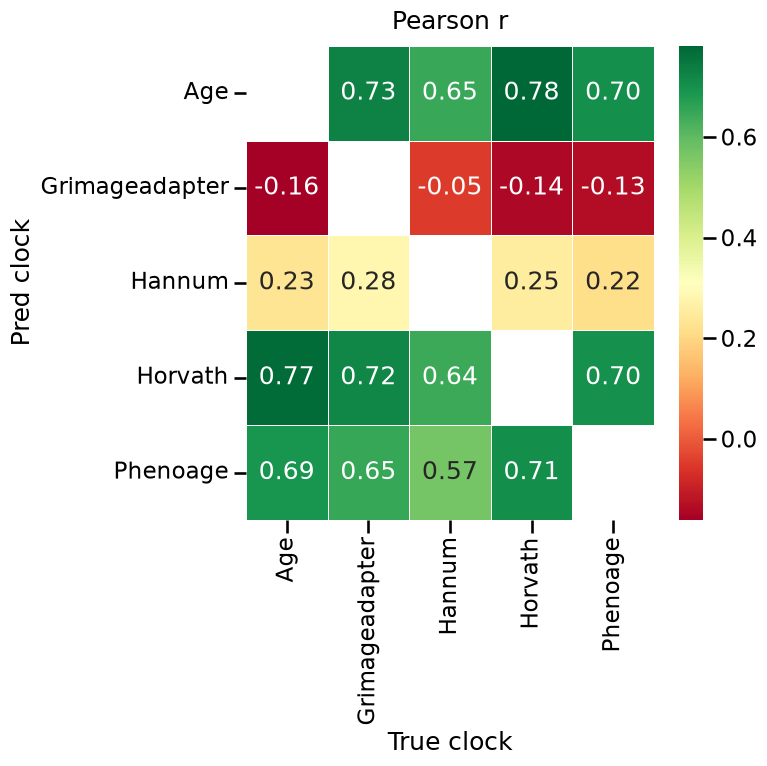

In [42]:
m = 'pearson_r'
fig_true  = eu.plot_metric_heatmap(eu.pairwise_metrics(predictions, clock_names, rows="true")[m], m)
fig_cross = eu.plot_metric_heatmap(cross[m] , m)

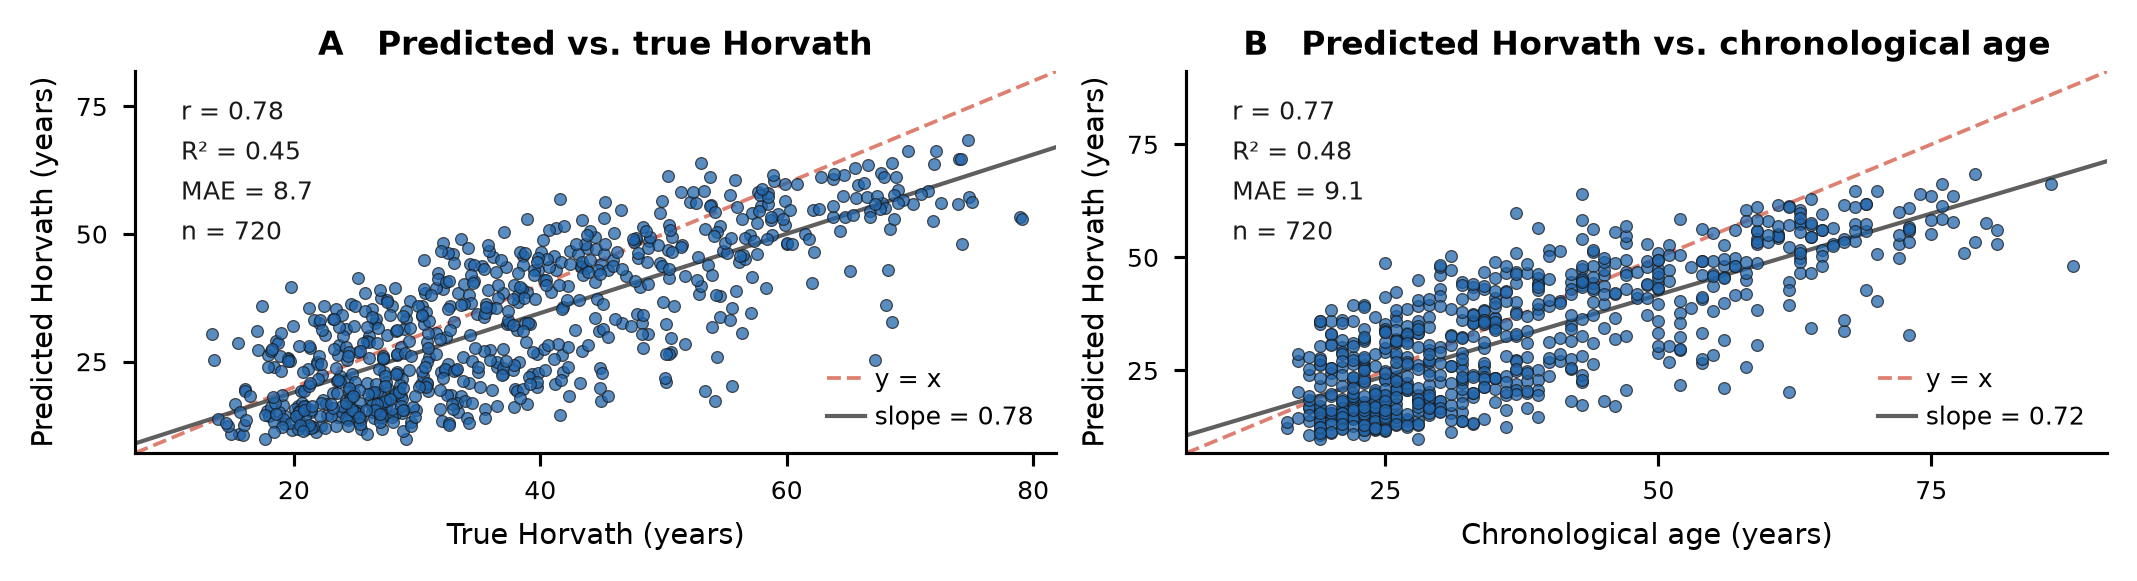

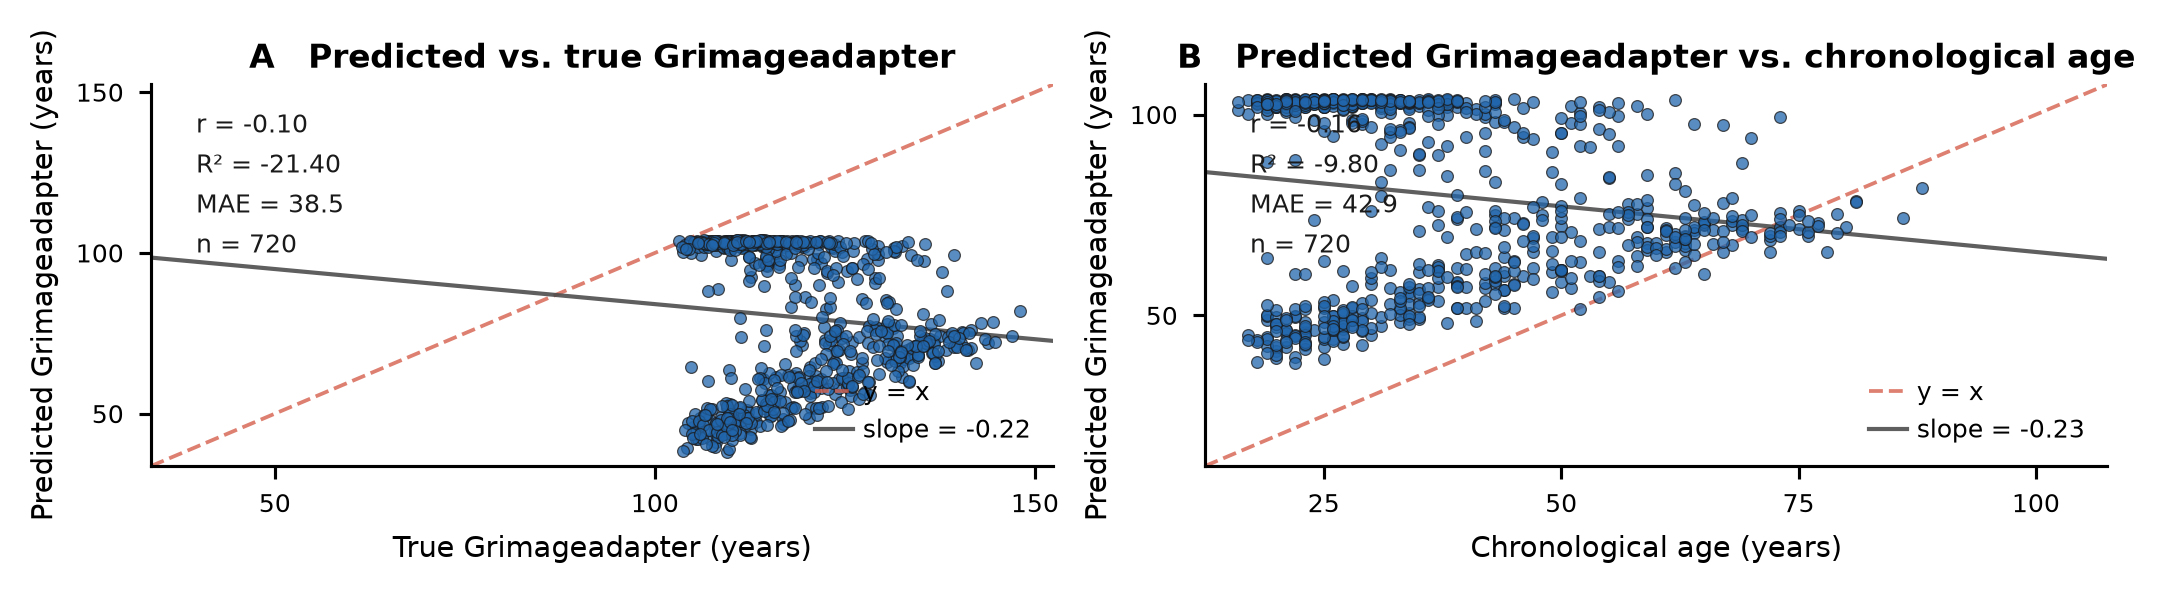

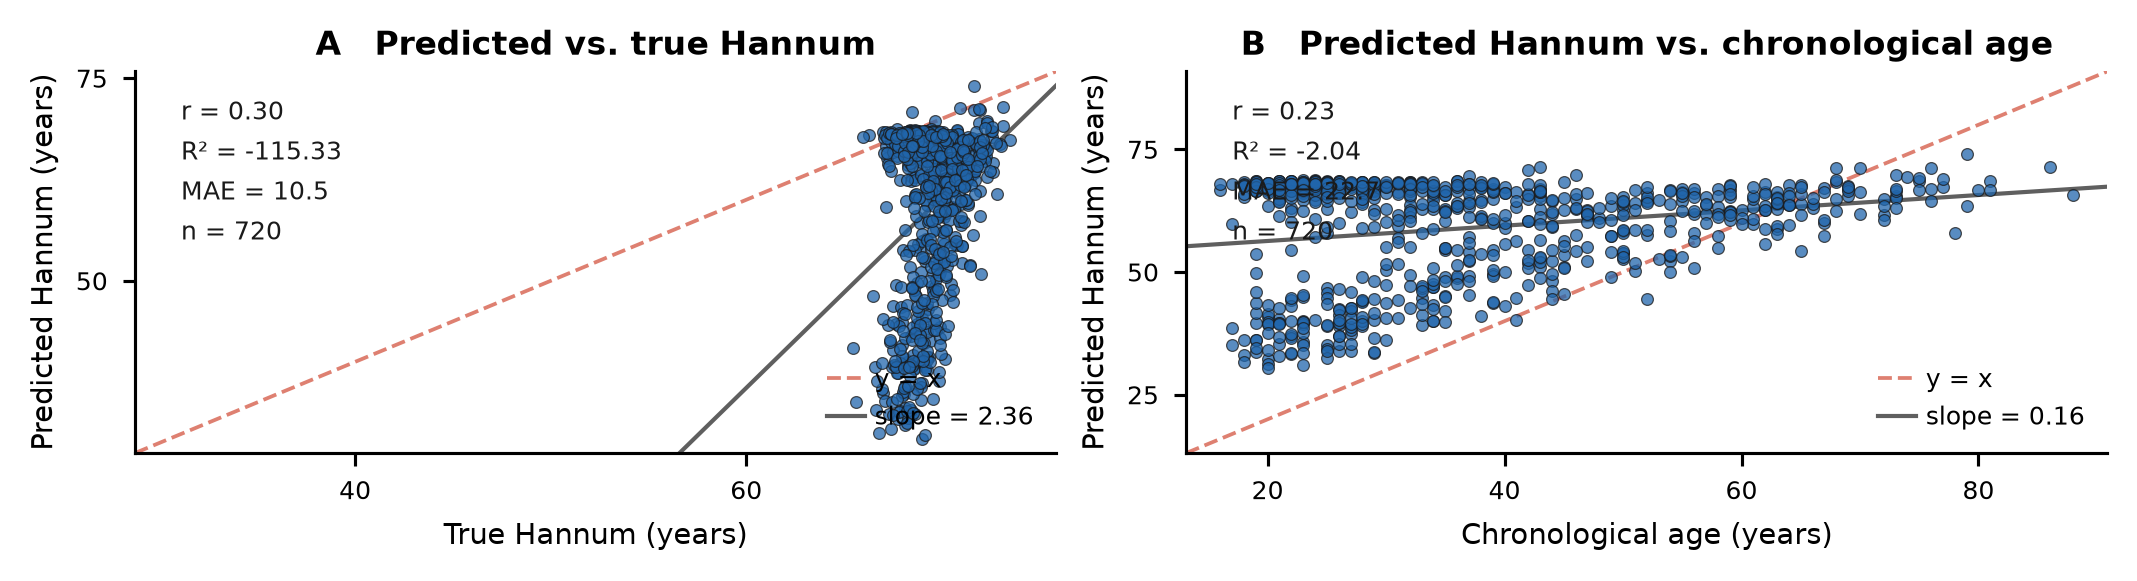

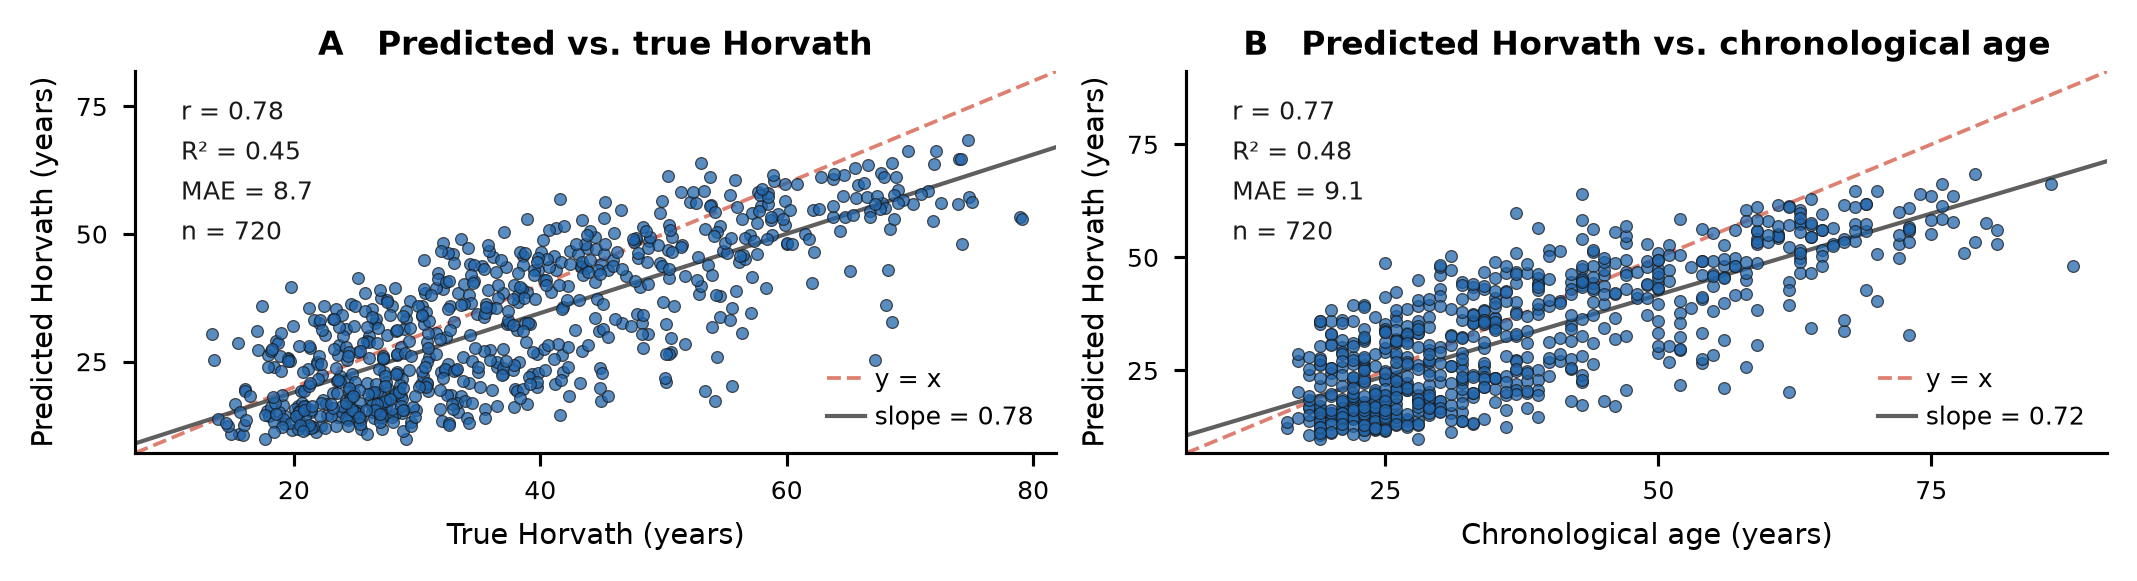

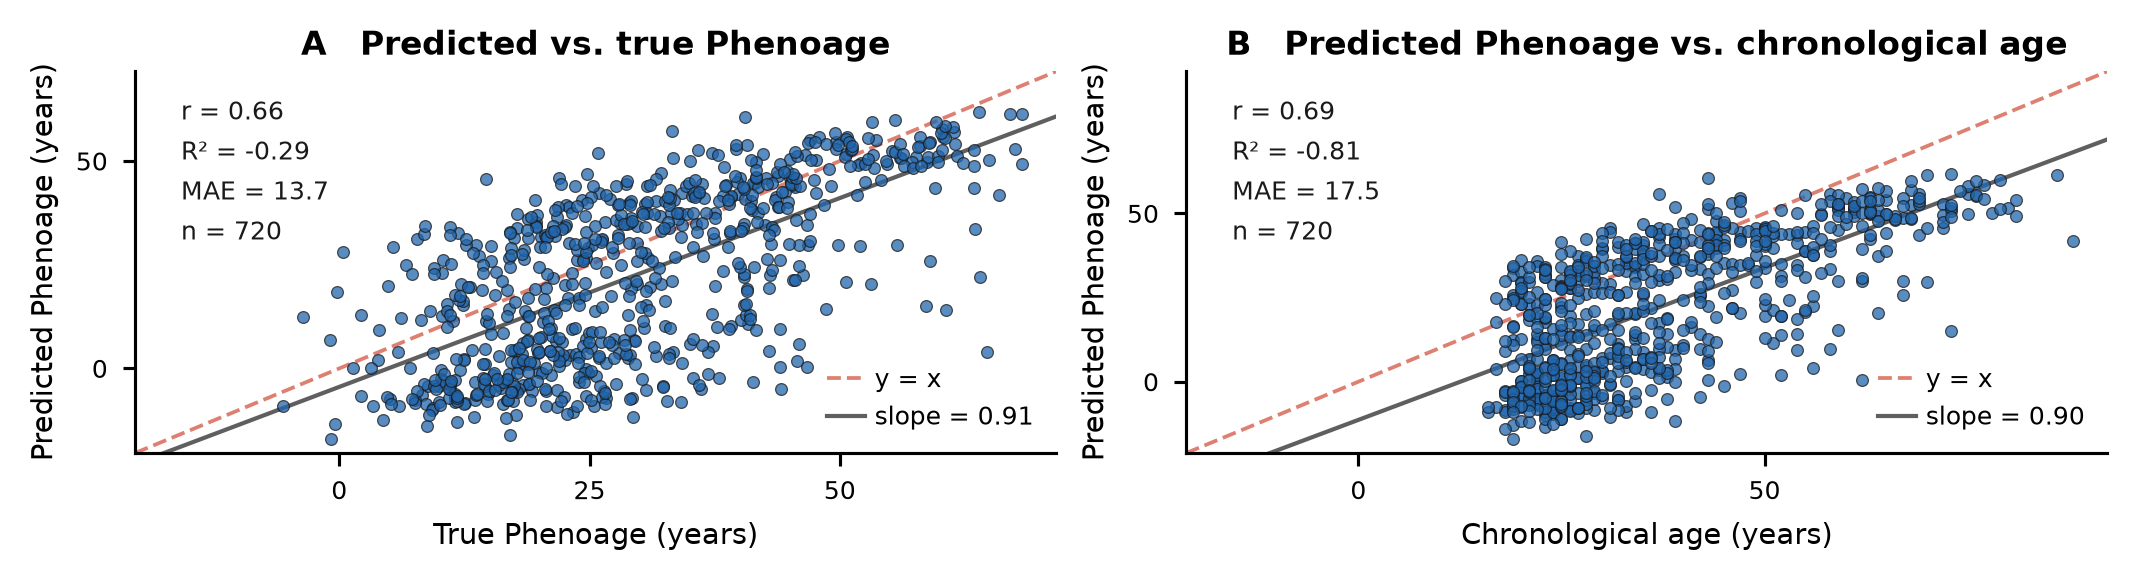

In [44]:
# One clock at a time
fig, (ax_a, ax_b), stats = eu.plot_clock_panels(
    predictions, "horvath_age",
    chron_clock  = "age",          # column to use as chronological age
    save_path    = None,   # saves .pdf + .png, or None
    fig_width_mm = 89,             # NM single-column width
)

# All clocks at once (skips chron_clock itself)
results = eu.plot_all_clock_panels(predictions, clock_names,
                                   chron_clock="age", save_dir=None)